In [1]:
import numpy as np
import pandas as pd
import emcee
from io import StringIO
CO, H2O, CO2, H2, CH2 = range(5)

raw_txt = """Experiment block\tTemp\tCO2 mL/min\tCO mL/min\tAr mL/min\tCO/Ar mL/min\tH2 mL/min\tTotal  mL/min\talpha\tPCO\tPCO2\tPH2
H2COVar\t513\t0\t56.84210526\t6.315789474\t63.15789474\t56.84210526\t120\t0.792973876\t2.368421053\t0\t2.368421053
H2COVar\t513\t0\t38.57142857\t4.285714286\t42.85714286\t77.14285714\t120\t0.783092833\t1.607142857\t0\t3.214285714
H2COVar\t513\t0\t29.18918919\t3.243243243\t32.43243243\t87.56756757\t120\t0.758648032\t1.216216216\t0\t3.648648649
TempVar(Only CO+H2)\t493.15\t0\t38.57142857\t4.285714286\t42.85714286\t77.14285714\t120\t0.828590544\t1.607142857\t0\t3.214285714
TempVar(Only CO+H2)\t513.15\t0\t38.57142857\t4.285714286\t42.85714286\t77.14285714\t120\t0.778061766\t1.607142857\t0\t3.214285714
TempVar(Only CO+H2)\t533.15\t0\t38.57142857\t4.285714286\t42.85714286\t77.14285714\t120\t0.68652452\t1.607142857\t0\t3.214285714
TempVar(Only CO+H2)\t553.15\t0\t38.57142857\t4.285714286\t42.85714286\t77.14285714\t120\t0.570689834\t1.607142857\t0\t3.214285714
TempVar(Only CO+H2)\t573.15\t0\t38.57142857\t4.285714286\t42.85714286\t77.14285714\t120\t0.484066337\t1.607142857\t0\t3.214285714
H2CO2Var\t513.15\t30\t0\t0\t0\t90\t120\t0.018953371\t0\t1.25\t3.75
H2CO2Var\t513.15\t40\t0\t0\t0\t80\t120\t0.024583548\t0\t1.666666667\t3.333333333
H2CO2Var\t513.15\t60\t0\t0\t0\t60\t120\t0.037047515\t0\t2.5\t2.5
TempVar(Only CO2+H2)\t493.15\t40\t0\t0\t0\t80\t120\t0.02664535\t0\t1.666666667\t3.333333333
TempVar(Only CO2+H2)\t513.15\t40\t0\t0\t0\t80\t120\t0.023100337\t0\t1.666666667\t3.333333333
TempVar(Only CO2+H2)\t533.15\t40\t0\t0\t0\t80\t120\t0.01438644\t0\t1.666666667\t3.333333333
TempVar(Only CO2+H2)\t553.15\t40\t0\t0\t0\t80\t120\t0.008155606\t0\t1.666666667\t3.333333333
TempVar(Only CO+CO2+H2)\t493.15\t19.81651376\t9.908256881\t1.01\t11.00917431\t89.17\t120\t0.536381781\t0.412844037\t0.825688073\t3.715416667
TempVar(Only CO+CO2+H2)\t513.15\t19.81651376\t9.908256881\t1.01\t11.00917431\t89.17\t120\t0.469369407\t0.412844037\t0.825688073\t3.715416667
TempVar(Only CO+CO2+H2)\t533.15\t19.81651376\t9.908256881\t1.01\t11.00917431\t89.17\t120\t0.26899611\t0.412844037\t0.825688073\t3.715416667
TempVar(Only CO+CO2+H2)\t553.15\t19.81651376\t9.908256881\t1.01\t11.00917431\t89.17\t120\t0.241802475\t0.412844037\t0.825688073\t3.715416667
TempVar(Only CO+CO2+H2)\t573.15\t19.81651376\t9.908256881\t1.01\t11.00917431\t89.17\t120\t0.235135057\t0.412844037\t0.825688073\t3.715416667
ConstH2CO2Var\t513.15\t10\t0\t80\t0\t30\t120\t0.017891062\t0\t0.416666667\t1.25
ConstH2CO2Var\t513.15\t15\t0\t75\t0\t30\t120\t0.022537633\t0\t0.625\t1.25
ConstH2CO2Var\t513.15\t30\t0\t60\t0\t30\t120\t0.034930099\t0\t1.25\t1.25
ConstH2COVar\t513.15\t0\t9.999\t80.001\t11.00917431\t30\t120\t0.627018131\t0.416625\t0\t1.25
ConstH2COVar\t513.15\t0\t15.003\t74.997\t16.67\t30\t120\t0.662211446\t0.625125\t0\t1.25
ConstH2COVar\t513.15\t0\t29.997\t60.007\t33.33\t30\t120\t0.728855629\t1.249875\t0\t1.25
ConstCOH2Var\t513.15\t0\t26.1\t32.68\t29\t58\t116.78\t0.685585374\t1.117485871\t0\t2.483301935
ConstCOH2Var\t513.15\t0\t26.1\t61.68\t29\t29\t116.78\t0.730646513\t1.117485871\t0\t1.241650968
ConstCOH2Var\t513.15\t0\t26.1\t32.68\t29\t58\t116.78\t0.721576582\t1.117485871\t0\t2.483301935
"""

df_raw = pd.read_csv(StringIO(raw_txt), sep=r"\t", engine="python")
df_raw.columns = [str(c).strip().replace("\u00a0", " ") for c in df_raw.columns]

# drop junk
drop_cols = [c for c in df_raw.columns if c.lower().startswith("column")]
df_raw = df_raw.drop(columns=drop_cols, errors="ignore")
df_raw = df_raw.dropna(axis=1, how="all")

rename_map = {
    "Experiment block": "block",
    "Temp": "T",
    "CO2 mL/min": "CO2",
    "CO mL/min": "CO",
    "Ar mL/min": "Ar",
    "CO/Ar mL/min": "CO_Ar",
    "H2 mL/min": "H2",
    "Total  mL/min": "Total",
    "H2:CO ratio": "H2_CO_ratio",
    "H2:CO2 ratio": "H2_CO2_ratio",
}
df = df_raw.rename(columns=rename_map).copy()

required = [
    "block","T","CO2","CO","Ar","CO_Ar","H2","Total",
    "alpha","PCO","PCO2","PH2"
]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns after cleaning: {missing}\nColumns found: {list(df.columns)}")

for c in required:
    if c != "block":
        df[c] = pd.to_numeric(df[c], errors="coerce")

df["block"] = df["block"].astype(str).str.strip()
df = df.dropna(subset=["block", "T", "alpha"]).copy()

bad_alpha = df[~df["alpha"].between(0.0, 1.0, inclusive="neither")]
if len(bad_alpha) > 0:
    print("Invalid alpha rows (must be 0<alpha<1):")
    display(bad_alpha[["block","T","alpha","CO2","CO","H2"]])
    raise ValueError("Invalid alpha values present.")

R = 8.314462618            # J/mol/K
P  =  1e5  # Pa (absolute)
T_ref = 500
eps = 1e-12

def logit(a):
    a = np.clip(np.asarray(a, float), eps, 1.0 - eps)
    return np.log(a / (1.0 - a))

def inv_logit(z):
    z = np.asarray(z, float)
    z = np.clip(z, -1000, 1000)
    return 1.0 / (1.0 + np.exp(-z))

def alpha_model(theta, T, C_CO, C_CO2, C_H2):
    k0, Ea, a, b, c = theta

    T = np.asarray(T, float)
    C_CO  = np.asarray(C_CO, float)
    C_CO2 = np.asarray(C_CO2, float)
    C_H2  = np.asarray(C_H2, float)

    CO_term  = (C_CO  + eps)**a
    CO2_term = (C_CO2 + eps)**b

    denom = k0 * np.exp(Ea/R*(1/T-1/T_ref)) * (CO_term + CO2_term)
    alpha = (1+(C_H2**c+eps)/(denom))**(-1)
    return np.clip(alpha, eps, 1.0 - eps)

T_arr  = df["T"].to_numpy(float)
C_CO   = df["CO"].to_numpy(float)
C_CO2  = df["CO2"].to_numpy(float)
C_H2   = df["H2"].to_numpy(float)

alpha_obs = df["alpha"].to_numpy(float)
y_obs = logit(alpha_obs)

def log_likelihood(theta):
    log_k0, Ea, a, b, c, log_sigma = theta
    sigma = np.exp(log_sigma)

    alpha_mu = alpha_model([log_k0, Ea, a, b, c], T_arr, C_CO, C_CO2, C_H2)
    mu = logit(alpha_mu)

    resid = y_obs - mu
    return -0.5 * np.sum((resid / sigma)**2 + 2*np.log(sigma) + np.log(2*np.pi))

def log_prior(theta):
    k0, Ea, a, b, c, log_sigma = theta
    lp = 0.0

    # log_k0 ~ N(0, 5^2)
    lp += -0.5 * (k0 / 0.1)**2 - np.log(0.1 * np.sqrt(2*np.pi))

    # Ea ~ N(Ea_lin, (5e4)^2)
    lp += -0.5 * ((Ea - 5000) / 5e4)**2 - np.log(5e4 * np.sqrt(2*np.pi))

    # bounds
    if not (0.0 <= a <= 3.0 and -3.0 <= b <= 3.0 and 0.0 <= c <= 3.0):
        return -np.inf

    # Half-Cauchy(2.5) on sigma via log_sigma (Jacobian included)
    sigma = np.exp(log_sigma)
    if sigma <= 0:
        return -np.inf
    lp += np.log(2/np.pi) - np.log(1 + (sigma/2.5)**2) + log_sigma
    return lp

def log_posterior(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta)


rng = np.random.default_rng(42)

theta0 = np.array([
    1.0,   # k0
    50001,         # Ea
    1.0,           # a
    1.0,           # b
    1.0,           # c
    np.log(0.5)    # log_sigma
], dtype=float)

ndim = theta0.size
nwalkers = 4 * ndim

p0 = theta0 + rng.normal(
    scale=[0.1, 5e3, 0.15, 0.15, 0.15, 0.15],
    size=(nwalkers, ndim)
)

sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior)

print("\n--- Burn-in ---")
state = sampler.run_mcmc(p0, 5000, progress=True)

sampler.reset()
print("\n--- Production ---")
sampler.run_mcmc(state, 15000, progress=True)

flat = sampler.get_chain(discard=0, thin=10, flat=True)
k0_s, Ea_s, a_s, b_s, c_s, log_sigma_s = [flat[:, i] for i in range(flat.shape[1])]
sigma_s = np.exp(log_sigma_s)

def summarize(x):
    x = np.asarray(x, float)
    return np.mean(x), np.std(x), np.percentile(x, [5, 50, 95])

print("\n--- Posterior summaries ---")
names = ["k0", "Ea", "a", "b", "c", "sigma"]
for nm, arr in zip(names, [k0_s, Ea_s, a_s, b_s, c_s, sigma_s]):
    m, sd, q = summarize(arr)
    print(f"{nm:8s}: mean={m:.6g}, sd={sd:.6g}, 95% CrI=({q[0]:.6g}, {q[2]:.6g})")




--- Burn-in ---


100%|██████████| 5000/5000 [00:08<00:00, 622.29it/s]



--- Production ---


100%|██████████| 15000/15000 [00:23<00:00, 646.31it/s]


--- Posterior summaries ---
k0      : mean=0.0827531, sd=0.0318125, 95% CrI=(0.0481844, 0.144878)
Ea      : mean=44183.6, sd=6313.76, 95% CrI=(33662.5, 54403.5)
a       : mean=1.22031, sd=0.0589863, 95% CrI=(1.12723, 1.31631)
b       : mean=-0.100501, sd=0.0211644, 95% CrI=(-0.122845, -0.0671653)
c       : mean=0.130046, sd=0.0885964, 95% CrI=(0.0120401, 0.294)
sigma   : mean=0.284487, sd=0.0442844, 95% CrI=(0.222116, 0.365376)


In [2]:
# =========================================================
# Bayesian uncertainty propagation through 50 CSTR stages
# Run this AFTER sampler.run_mcmc(...)
# =========================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Extract posterior samples
# ---------------------------------------------------------

flat = sampler.get_chain(
    discard=0,
    thin=10,
    flat=True
)

print("Posterior sample array:", flat.shape)

rng = np.random.default_rng(123)

n_draws = min(3000, len(flat))
indices = rng.choice(
    len(flat),
    size=n_draws,
    replace=False
)

posterior_draws = flat[indices]

# ---------------------------------------------------------
# 2. Initial conditions
# ---------------------------------------------------------

R_CSTR = 8.314462618
T_CSTR = 473.0
T_REF_CSTR = 500.0

N = 50
tau = 35.55

# Total pressure: 0.5 MPa = 5e5 Pa
P_total = 0.5e6

# Equilibrium composition at 1000 K
T_equilibrium = 1000.0

K_eq = np.exp(
    -13.148
    + 1.077 * np.log(T_equilibrium)
    + 5.44e-4 * T_equilibrium
    - 1.125e-7 * T_equilibrium**2
    + 5693.5 / T_equilibrium
    - 49170.0 / T_equilibrium**2
)

sqrt_K = np.sqrt(K_eq)

y_CO = 1.0 / (2.0 * (1.0 + sqrt_K))
y_CO2 = sqrt_K / (2.0 * (1.0 + sqrt_K))
y_H2 = sqrt_K / (2.0 * (1.0 + sqrt_K))

P_CO0 = y_CO * P_total
P_CO20 = y_CO2 * P_total
P_H20 = y_H2 * P_total

C_CO0 = P_CO0 / (R_CSTR * T_CSTR)
C_CO20 = P_CO20 / (R_CSTR * T_CSTR)
C_H20 = P_H20 / (R_CSTR * T_CSTR)

print("Initial concentrations:")
print("CO :", C_CO0)
print("CO2:", C_CO20)
print("H2 :", C_H20)

Posterior sample array: (36000, 6)
Initial concentrations:
CO : 28.87257997976242
CO2: 34.696318035535
H2 : 34.696318035535


In [3]:
# ---------------------------------------------------------
# 3. Stage alpha model
# ---------------------------------------------------------

def alpha_stage(theta, T, C_CO, C_CO2, C_H2):
    """
    theta = [log_k0, Ea, a, b, c, log_sigma]
    """

    log_k0, Ea, a, b, c = theta[:5]

    # Your Bayesian code samples log_k0,
    # therefore convert it back to k0.
    k0 = np.exp(log_k0)

    CO_term = (C_CO + 1e-12) ** a
    CO2_term = (C_CO2 + 1e-12) ** b

    denominator = (
        k0
        * np.exp(
            Ea / R_CSTR
            * (1.0 / T - 1.0 / T_REF_CSTR)
        )
        * (CO_term + CO2_term)
    )

    alpha = (
        1.0
        + (C_H2 + 1e-12) ** c
        / (denominator + 1e-12)
    ) ** (-1.0)

    return np.clip(alpha, 1e-12, 1.0 - 1e-12)

In [4]:
# ---------------------------------------------------------
# 4. Simulate all posterior samples
# ---------------------------------------------------------

# Set this to your physical kinetic coefficient.
# Increase it to obtain more concentration change.
k_rate = 1.0e-4

# Stoichiometry:
# 1 mol CO consumed -> 1 mol CO2 produced
# 2 mol H2 consumed
nu_CO2 = 1.0
nu_H2 = 2.0

alpha_samples = np.zeros((n_draws, N + 1))
CO_samples = np.zeros((n_draws, N + 1))
CO2_samples = np.zeros((n_draws, N + 1))
H2_samples = np.zeros((n_draws, N + 1))

for j, theta in enumerate(posterior_draws):

    # Stage 0 is the reactor inlet
    CO_samples[j, 0] = C_CO0
    CO2_samples[j, 0] = C_CO20
    H2_samples[j, 0] = C_H20

    alpha_samples[j, 0] = alpha_stage(
        theta,
        T_CSTR,
        CO_samples[j, 0],
        CO2_samples[j, 0],
        H2_samples[j, 0]
    )

    for stage in range(1, N + 1):

        # Inlet values to the current CSTR
        CO_in = CO_samples[j, stage - 1]
        CO2_in = CO2_samples[j, stage - 1]
        H2_in = H2_samples[j, stage - 1]

        alpha_in = alpha_samples[j, stage - 1]

        # Reaction-rate model
        rate = (
            alpha_in
            * k_rate
            * CO_in
            * np.sqrt(max(H2_in, 0.0))
        )

        # Reaction during one CSTR residence time
        delta_CO = tau * rate

        # Prevent negative concentrations
        delta_CO = min(delta_CO, CO_in)

        # Update concentrations
        CO_samples[j, stage] = CO_in - delta_CO

        CO2_samples[j, stage] = (
            CO2_in + nu_CO2 * delta_CO
        )

        H2_samples[j, stage] = max(
            H2_in - nu_H2 * delta_CO,
            0.0
        )

        # Alpha at the outlet of the current CSTR
        alpha_samples[j, stage] = alpha_stage(
            theta,
            T_CSTR,
            CO_samples[j, stage],
            CO2_samples[j, stage],
            H2_samples[j, stage]
        )

In [5]:
# ---------------------------------------------------------
# 5. Calculate 5%, 50%, and 95% intervals
# ---------------------------------------------------------

def get_interval(samples):
    lower = np.percentile(samples, 5, axis=0)
    median = np.percentile(samples, 50, axis=0)
    upper = np.percentile(samples, 95, axis=0)
    return lower, median, upper


alpha_low, alpha_med, alpha_high = get_interval(
    alpha_samples
)

CO_low, CO_med, CO_high = get_interval(
    CO_samples
)

CO2_low, CO2_med, CO2_high = get_interval(
    CO2_samples
)

H2_low, H2_med, H2_high = get_interval(
    H2_samples
)

stages = np.arange(N + 1)

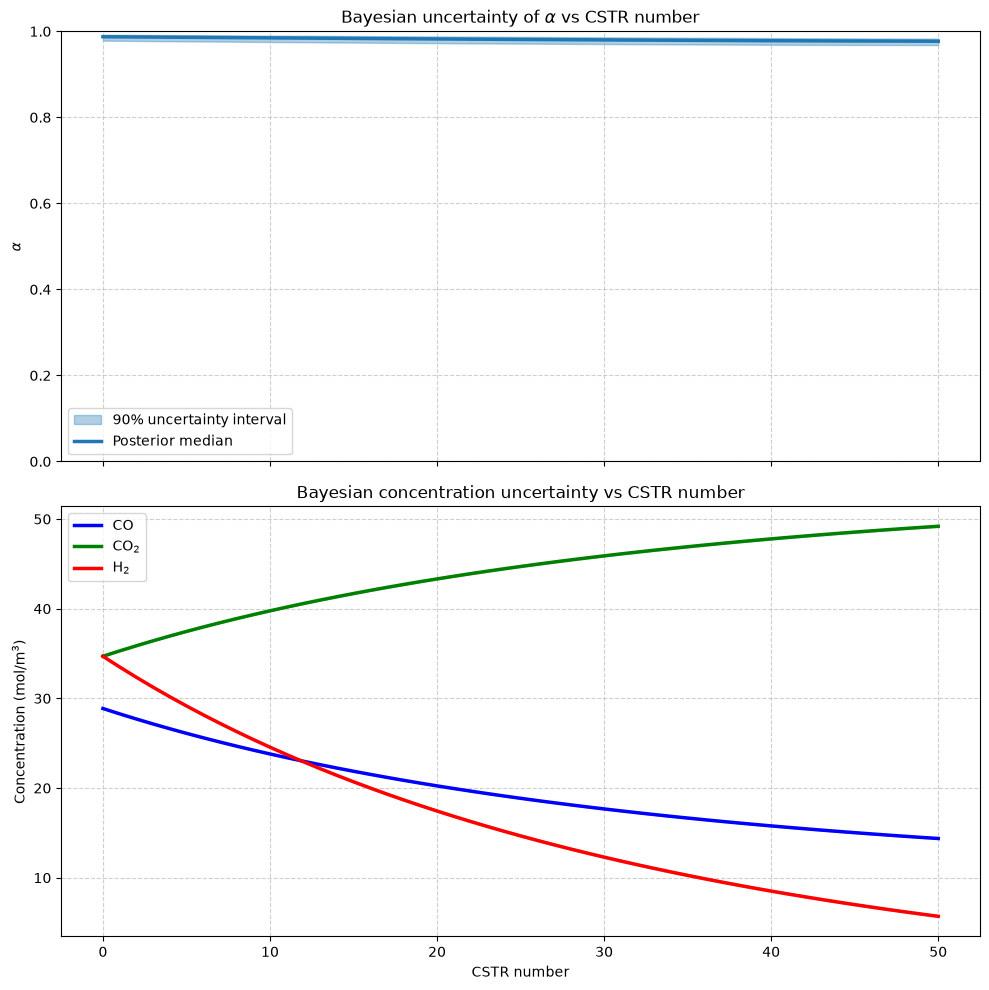

In [6]:
# ---------------------------------------------------------
# 6. Plot uncertainty graphs
# ---------------------------------------------------------

fig, ax = plt.subplots(
    2,
    1,
    figsize=(10, 10),
    sharex=True
)

# =========================================================
# Alpha plot
# =========================================================

ax[0].fill_between(
    stages,
    alpha_low,
    alpha_high,
    color="tab:blue",
    alpha=0.35,
    label="90% uncertainty interval"
)

ax[0].plot(
    stages,
    alpha_med,
    color="tab:blue",
    linewidth=2.5,
    label="Posterior median"
)

ax[0].set_ylabel(r"$\alpha$")
ax[0].set_title(r"Bayesian uncertainty of $\alpha$ vs CSTR number")
ax[0].set_ylim(0, 1)
ax[0].grid(True, linestyle="--", alpha=0.6)
ax[0].legend()


# =========================================================
# Concentration plot
# =========================================================

ax[1].fill_between(
    stages,
    CO_low,
    CO_high,
    color="blue",
    alpha=0.30
)

ax[1].plot(
    stages,
    CO_med,
    color="blue",
    linewidth=2.5,
    label="CO"
)

ax[1].fill_between(
    stages,
    CO2_low,
    CO2_high,
    color="green",
    alpha=0.30
)

ax[1].plot(
    stages,
    CO2_med,
    color="green",
    linewidth=2.5,
    label="CO$_2$"
)

ax[1].fill_between(
    stages,
    H2_low,
    H2_high,
    color="red",
    alpha=0.30
)

ax[1].plot(
    stages,
    H2_med,
    color="red",
    linewidth=2.5,
    label="H$_2$"
)

ax[1].set_xlabel("CSTR number")
ax[1].set_ylabel("Concentration (mol/m$^3$)")
ax[1].set_title(
    "Bayesian concentration uncertainty vs CSTR number"
)
ax[1].grid(True, linestyle="--", alpha=0.6)
ax[1].legend()

plt.tight_layout()
plt.show()